# エタノール27分子：GROMACS NVTを理解する

**到達目標**：初期条件を再現し、GROMACSの入力と出力を追跡し、短時間RDFを正しく読めるようになる。

300 K・体積固定・0.5 fs・600 steps・拘束なし。100 fsを準備区間、続く200 fsを解析区間とする。これは習熟用の短い計算で、平衡物性は評価しない。

まず第0〜4節を実行する。QM/RESPが未準備でも学べる。第5節以降は必要な入力を用意した後に実行する。セルはMDや外部QMを自動開始しない。詳細：[教材README](../README.md)。


## 0. 場所と環境を確認する

Notebookをどこから開いてもrepositoryを探す。`BUILD` は構造生成の出力、`RUN` はMDの出力。実行結果はGit管理しない `runs/` に保存する。

予想：ASE、NumPy、RDKitがあれば前半は実行できる。GROMACSが存在しても、実行可能とは限らない。


In [ ]:
from pathlib import Path
import sys, json, importlib.metadata as metadata
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/mdworkbench").is_dir()), None)
if ROOT is None:
    raise RuntimeError("GROMACS-MD-v1内からNotebookを開いてください")
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from mdworkbench.ethanol_benchmark import config, build
from mdworkbench.analysis.ethanol_rdf import intermolecular_rdf, production_indices
CONFIG = ROOT / "systems/ethanol_27/system.yaml"
BUILD = ROOT / "runs/ethanol27_initial"
RUN = ROOT / "runs/ethanol27_nvt"
cfg = config(CONFIG)
print("ROOT:", ROOT)
print("Python:", sys.executable)
for name in ["ase", "numpy", "rdkit", "MDAnalysis", "mace-torch"]:
    try: print(name, metadata.version(name))
    except metadata.PackageNotFoundError: print(name, "未導入")
print("仕様で再現対象のversion: ASE 3.29.0 / mace-torch 0.3.16")


ROOT: [ローカルのリポジトリパスを省略]
Python: [ローカルのPythonパスを省略]
ase 3.29.0
numpy 1.26.4
rdkit 2026.3.1
MDAnalysis 2.10.0
mace-torch 0.3.16
仕様で再現対象のversion: ASE 3.29.0 / mace-torch 0.3.16


## 1. 1分子から27分子へ：予想してから作る

ASEのエタノール1分子をCOM中心化し、x軸を(1,1,1)へ向ける。格子の中心 `(index+0.5)×4.6 Å` に配置する。この原点の選択は仕様書にない実装上の約束であり、全体の平行移動に相当する。seed42の独立RNGで各分子にx→y→zの微小回転を加える。

**問い**：9原子×27分子、13.8 Åの立方体なら密度はどのくらいになるか。体積は辺の長さの何乗か。

出力が既存なら読み込む。再作成のために削除せず、BUILDを新しい名前に変える。


In [2]:
if not BUILD.exists():
    build(cfg, BUILD)
report = json.loads((BUILD / "build_report.json").read_text())
data = np.load(BUILD / "initial.npz")
positions = data["positions_A"]
for key in ["atom_count", "molecule_count", "molecular_mass_amu", "volume_A3", "density_g_cm3", "density_warning"]:
    print(key, report[key])
assert positions.shape == (243, 3)
print("ASE原子順:", list(enumerate(report["ase_single_symbols"])))


atom_count 243
molecule_count 27
molecular_mass_amu 46.068999999999996
volume_A3 2628.0720000000015
density_g_cm3 0.7859309429111057
density_warning False
ASE原子順: [(0, 'C'), (1, 'C'), (2, 'O'), (3, 'H'), (4, 'H'), (5, 'H'), (6, 'H'), (7, 'H'), (8, 'H')]


### 箱と分子を描く

描画のためだけに座標を箱へ折り返す。MD入力は元の座標を保つ。境界を跨ぐ共有結合は折り返し表示で長く見えるため、その線を省略する。色はC=黒、O=赤、H=灰。

**グラフの読み方**：3×3×3配置が残っているか。周期箱では右端の原子から左端の原子への距離は、図の直線距離と同じか。


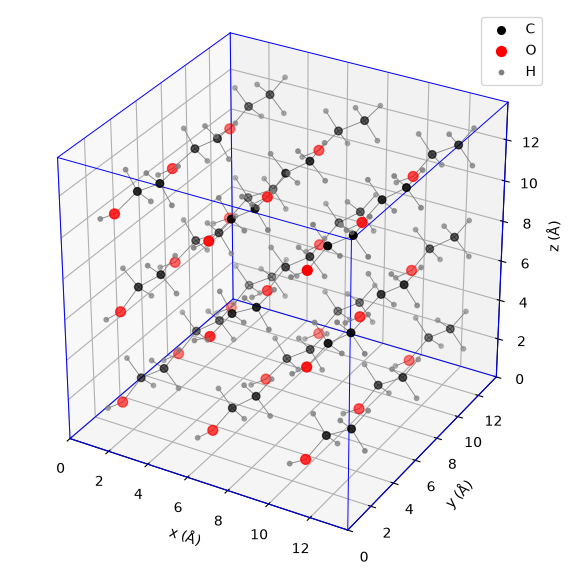

In [3]:
import itertools
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")
wrapped = positions % 13.8
symbols = np.tile(report["ase_single_symbols"], 27)
for symbol, color, size in [("C", "black", 30), ("O", "red", 50), ("H", "gray", 10)]:
    xyz = wrapped[symbols == symbol]
    ax.scatter(*xyz.T, c=color, s=size, label=symbol)
for molecule in range(27):
    for i, j in report["ase_single_bonds"]:
        xyz = wrapped[[9*molecule+i, 9*molecule+j]]
        if np.linalg.norm(xyz[0]-xyz[1]) < 2:
            ax.plot(*xyz.T, color="gray", lw=.6)
for a in itertools.product([0, 13.8], repeat=3):
    for axis in range(3):
        if a[axis] == 0:
            b = list(a); b[axis] = 13.8
            ax.plot(*np.array([a,b]).T, color="blue", lw=.7)
ax.set(xlabel="x (Å)", ylabel="y (Å)", zlabel="z (Å)", xlim=(0,13.8), ylim=(0,13.8), zlim=(0,13.8))
ax.set_box_aspect((1,1,1)); ax.legend(); plt.show()


## 2. 初期速度：温度とCOMを分けて考える

原子ごとの運動量は `p_i = sqrt(m_i k_B T) ξ_i`（ξは標準正規乱数）。全系のCOM運動を1回引き、運動エネルギー `K=Σ p_i²/(2m_i)` に対して `T=2K/(f k_B)` が300 Kとなるよう全運動量を1回スケールする。

COMの並進3自由度を除いた `f=3×243−3=726` を初期化で採用する。ASEと、MD中のCOM除去を無効にしたGROMACSは729自由度で温度を表示するため、同じ速度でも約298.765 Kとなる。これは初期データとtemperature表示の定義差である。thermostatのref-tは300 K。

**問い**：一回の初期スケールと、MD中のthermostatの役割はどう違うか。各分子のCOM速度もゼロになっているか。


COM速度 (nm/ps): [-1.05322143e-17 -3.24892035e-17 -2.15999649e-17]
T (726 DoF): 299.9999999999999
T (729 DoF): 298.76543209876536
各分子COM速度の最大絶対値 (nm/ps): 0.5464433379604247


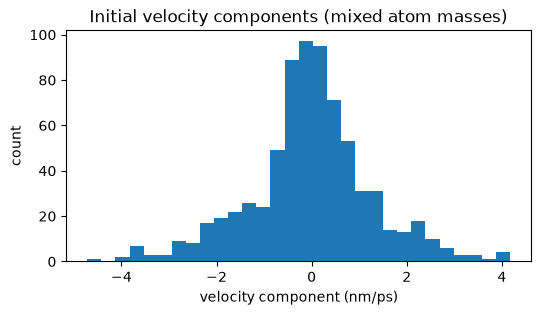

In [4]:
v = data["velocities_nm_ps"]
m = data["masses_amu"]
print("COM速度 (nm/ps):", (m[:,None] * v).sum(axis=0) / m.sum())
print("T (726 DoF):", report["temperature_726_dof_K"])
print("T (729 DoF):", report["temperature_729_dof_K"])
molecular_com_v = (m[:,None] * v).reshape(27,9,3).sum(axis=1) / m.reshape(27,9).sum(axis=1)[:,None]
print("各分子COM速度の最大絶対値 (nm/ps):", np.abs(molecular_com_v).max())
assert np.allclose((m[:,None]*v).sum(axis=0), 0, atol=1e-10)
assert abs(report["temperature_726_dof_K"]-300) < 1e-8
fig, ax = plt.subplots(figsize=(6,3))
ax.hist(v.ravel(), bins=30)
ax.set(xlabel="velocity component (nm/ps)", ylabel="count", title="Initial velocity components (mixed atom masses)")
plt.show()


## 3. RDFを初期配置で練習する

RDF `g(r)` は、中心から距離rに相手原子が現れる頻度を一様配置と比較したもの。今回は各分子からOとOHのHを一つずつ選び、**別分子だけ**数える。同一分子のOH共有結合は除外する。

`g(r) = histogram / [N_frame × 27 × (26/V) × shell_volume]`

`V=13.8³ Å³`、shell_volume=`4π/3 (r_outer³−r_inner³)`。OOも中心→相手の方向付きで数える。minimum imageで `Δr ← Δr−L round(Δr/L)` とする。45bin、r_max=6.762 Å。この節は1枚の初期構造の演習であり、production RDFではない。

**予想**：格子に由来する鋭いピークが現れるか。OH RDFが短距離にピークを持っても、水素結合を角度込みで数えたことになるか。


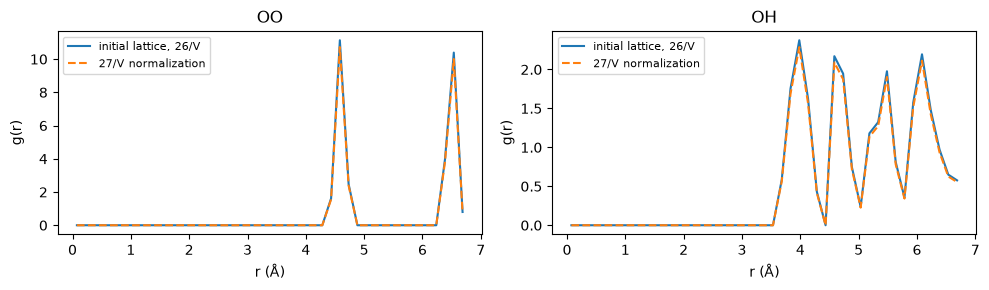

bin幅 (Å): 0.15026666666666666


In [5]:
ids = data["molecule_ids"]
oxygen = np.arange(27)*9 + report["oxygen_ase_index"]
hydroxyl_h = np.arange(27)*9 + report["hydroxyl_h_ase_index"]
initial_rdf = intermolecular_rdf(positions[None,:,:], np.array([[13.8]*3]), ids, oxygen, hydroxyl_h)
fig, axes = plt.subplots(1,2,figsize=(10,3))
for ax, name in zip(axes, ["OO", "OH"]):
    ax.plot(initial_rdf["r_A"], initial_rdf[name], label="initial lattice, 26/V")
    ax.plot(initial_rdf["r_A"], initial_rdf[name]*26/27, "--", label="27/V normalization")
    ax.set(xlabel="r (Å)", ylabel="g(r)", title=name)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("bin幅 (Å):", 6.762/45)


## 4. 解析frameを取り違えない

0.5 fs×stepが時刻。5stepごとの保存は2.5 fs間隔。step200を含めず、step205〜600を解析する。80frameは互いに相関するため、80個の独立した標本とは限らない。

**小課題**：step200を含めたら何枚になるか。次のassertを書き換えずに説明する。


In [6]:
saved_steps = np.arange(0, 601, 5)
selected = saved_steps[production_indices(saved_steps)]
print("frame数:", len(selected), "steps:", selected[0], "〜", selected[-1])
print("時刻 (ps):", selected[0]*.0005, "〜", selected[-1]*.0005)
assert len(selected)==80 and 200 not in selected


frame数: 80 steps: 205 〜 600
時刻 (ps): 0.10250000000000001 〜 0.3


## 5. RESPとGAFF：MDの前に入力を読む

RESPにはQM geometry・計算method/basis・ESP条件・fit条件・9原子の電荷と原子順序が必要。今は未準備である。nullを仮の値で埋めず、実際の入力を用意する。READMEの手順でSDF→AmberTools→ACPYPEを使うか、検証済み単分子topologyを用意する。

`system.yaml` の `structure.ase_atom_order` はtopology順からASE順へのmapping。Hを違うHへ取り違えると、元素数が正しくても速度・電荷・結合が対応しない。

**確認表**：GAFF/GAFF2、RESP出典、atom type/charge、bond/angle/dihedral/improper、LJ、combination rule、exclusion、1–4 Coulomb/LJ、cutoff、長距離処理。prepare出力の `force_field_report.json` とtopology snapshotを照合する。


In [7]:
cfg = config(CONFIG)
for section in ["force_field", "resp", "nonbonded", "review"]:
    print(section, json.dumps(cfg[section], ensure_ascii=False, indent=2))
print("未準備の場合はREADMEを参照。次のMD commandは自動実行しません。")


force_field {
  "family": null,
  "charge_model": "resp"
}
resp {
  "qm_backend": null,
  "method": null,
  "basis": null,
  "geometry_file": null,
  "esp_conditions": null,
  "fitting_conditions": null,
  "source_kind": "charges",
  "source_file": null,
  "atom_order_confirmed": false,
  "fit_inputs": []
}
nonbonded {
  "coulombtype": null,
  "rcoulomb_nm": null,
  "vdwtype": null,
  "rvdw_nm": null,
  "rlist_nm": null,
  "dispersion_correction": null,
  "adoption_reason": null
}
review {
  "force_field_parameters_confirmed": false,
  "max_force_kJ_mol_nm": null,
  "catastrophic_distance_A": 0.5
}
未準備の場合はREADMEを参照。次のMD commandは自動実行しません。


## 6. GROMACSの入力を実行へつなぐ

repository rootのterminalでREADMEの `prepare → preflight → run → analyze` を実行する。

| ファイル | 何を表すか | 点検する内容 |
|---|---|---|
| initial.gro | 座標nm、速度nm/ps、box | 原子順と速度が残っているか |
| topology/system.top + includes | 相互作用 | [molecules]が27、電荷と1–4規則 |
| nvt.mdp | 積分・温度制御・保存 | md-vv、constraints none、gen-vel no |
| nvt.tpr | gromppで統合したrun input | warningなし、自由度・質量の解釈 |
| nvt.log / EDR | 計算ログ・エネルギー | step600、温度・forceの異常 |
| nvt.xtc | 軌跡 | box固定、時間とframe数 |
| metadata.json | 出典とhash | version・command・入力の追跡 |

preflightは元の座標で0-stepのenergy/forceを評価する。問題があればEMをせず停止。NVTは元の初期速度から600stepを連続実行し、equilibration/productionの分割は解析時だけ行う。

**問い**：`gen-vel=yes` にすると何が比較不能になるか。`constraints=h-bonds` にすると、0.5 fs以外に何が変わるか。


In [ ]:
if (RUN/"nvt.mdp").exists():
    print((RUN/"nvt.mdp").read_text())
else:
    print("未prepare：必要なRESP・topology等を用意してREADMEのcommandを実行してください。")
print("NHC: tdamp=50 fs → tau_t≈2π×0.05=0.314159 ps, chain length=3")


## 7. 温度・Potentialを読む（実MD出力がある場合）

温度は常に300 Kに固定されるわけではない。NHCは熱浴とのエネルギー交換で温度分布を制御する。100 fsは平衡化を保証する長さではない。PotentialはkJ/mol（シミュレーションboxの系）で表示する。異なるpotential間ではエネルギー原点が異なり、絶対値の一致を期待しない。

**見る順序**：時間の単位→100 fs境界→不連続や発散→変動の時間尺度。平均が300 Kに近いだけで、平衡を断定しない。


In [ ]:
trace = RUN / "thermodynamics.xvg"
if trace.exists():
    from mdworkbench.ethanol_benchmark import read_thermodynamics
    time_ps, temperature_K, potential_kJ_mol = read_thermodynamics(trace)
    print("GROMACSのseries labels:")
    print("".join(line for line in trace.read_text().splitlines(True) if 'legend' in line))
    fig, axes = plt.subplots(2,1,figsize=(8,5),sharex=True)
    for ax, series, label in [(axes[0],temperature_K,"Temperature (K)"),(axes[1],potential_kJ_mol,"Potential (kJ/mol)")]:
        ax.plot(time_ps*1000, series); ax.axvline(100,color="gray",ls="--")
        ax.set_ylabel(label)
    axes[0].axhline(300,color="red",ls=":")
    axes[1].set_xlabel("time (fs)"); plt.tight_layout(); plt.show()
else:
    print("実MDは未実行：thermodynamics.xvg が生成された後に再実行してください。")


## 8. Production RDFと将来のMACE比較

80frameの平均でも200 fsしかない。初期配置の記憶が残る可能性が高い。ピークの位置と高さを初期RDFと比較し、変化の意味と不確かさを分けて説明する。

MACE referenceが将来できたら、READMEのadapter経由で同じ関数へ渡す。現在はreferenceがないため曲線を生成しない。potentialが違うのでtrajectory/RDFの一致は目的ではない。


In [ ]:
rdf_path = RUN / "rdf_gromacs.npz"
if rdf_path.exists():
    rdf_data = np.load(rdf_path)
    assert np.array_equal(rdf_data["steps"], np.arange(205,601,5))
    fig, axes = plt.subplots(1,2,figsize=(10,3))
    for ax, name in zip(axes,["OO","OH"]):
        ax.plot(initial_rdf["r_A"],initial_rdf[name],":",label="initial lattice")
        ax.plot(rdf_data["r_A"],rdf_data[name],label="GROMACS, 80 frames / 200 fs")
        if (RUN/"rdf_mace.npz").exists():
            reference=np.load(RUN/"rdf_mace.npz")
            ax.plot(reference["r_A"],reference[name],label="MACE reference")
        ax.set(xlabel="r (Å)",ylabel="g(r)",title=name); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()
else:
    print("production RDF未生成：MD後に analyze commandを実行してください。")


## 9. 自分の言葉で説明する

1. 初期条件が同じでもpotentialが違うと加速度・trajectoryはなぜ変わるか。
2. thermostatの質量を対応させても積分方法・自由度・内部状態の差は何か。
3. 拘束なしで0.5 fsを使う理由は何か。
4. 200 fs/80frameで収束RDFを主張できない理由は何か。
5. OOとOH RDFの違いと、角度を含む水素結合判定の違いは何か。
6. 初期格子の影響はどの曲線にどう見えたか。
7. 26/Vと27/VでRDFが26/27倍になる理由を説明する。
8. 「条件を揃える」で揃えたものと、未検証・異なるものを列挙する。

### 観察メモ（ここへ記入）

- 実行済みの範囲：
- 確認したversionとhash：
- 予想と実際の違い：
- 未準備の科学入力：
- 結果から言えること：
- まだ言えないこと：

出典：[GROMACS MDP](https://manual.gromacs.org/documentation/current/user-guide/mdp-options.html)、[GROMACS thermostat](https://manual.gromacs.org/2022/reference-manual/algorithms/molecular-dynamics.html)、[ASE NHC implementation](https://docs.ase-lib.org/_modules/ase/md/nose_hoover_chain.html)。採用値と温度定義の差はREADMEを参照。
